# 9장 · 출력층 — 벡터를 다음 단어 확률로 🎲

웹 챕터 **"출력층"** 과 짝을 이루는 실습입니다.
마지막 문맥 벡터를 **사전 전체 단어의 점수(logits)** 로 바꾸고 **소프트맥스**로 확률을 냅니다.
(워밍업 ch00 소프트맥스와 하나로 이어집니다)

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터**: 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요. 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요
from tutor import chat

chat('ch9')

## 1. 사전과 출력 벡터

"오늘 날씨가 정말 ___" 후보 단어들과 각 단어의 출력 벡터(방향). (웹 실험실과 같은 값)

In [1]:
import numpy as np

VOCAB = ['좋다', '춥다', '덥다', '흐리다', '사과', '달린다']
W_out = np.array([[ 1.0, 0.3], [0.3, 1.0], [-0.3, 1.0],
                  [-1.0, 0.3], [0.2,-1.0], [-0.6,-0.8]])   # 출력층 가중치(단어 벡터)

def softmax(z):
    z = np.asarray(z, float); z = z - z.max()
    e = np.exp(z); return e / e.sum()

## 2. 벡터 → 점수(logits) → 확률

출력층은 **문맥 벡터 · 각 단어 벡터**(내적)로 점수를 냅니다. 행렬 한 번 곱으로 전부 계산돼요.
$$\text{logits} = \text{context} \cdot W_{out}^\top, \quad P = \text{softmax}(\text{logits})$$

In [2]:
context = np.array([1.0, 0.2])   # 블록들을 다 통과한 마지막 벡터
logits = W_out @ context         # 단어마다 점수 하나씩
probs = softmax(logits)

for w, z, p in zip(VOCAB, logits, probs):
    print(f'{w:5s}: 점수 {z:5.2f} → 확률 {p*100:5.1f}%')
print('확률 합:', round(probs.sum(), 6))
print('다음 단어 →', VOCAB[int(np.argmax(probs))])

좋다   : 점수  1.06 → 확률  39.5%
춥다   : 점수  0.50 → 확률  22.6%
덥다   : 점수 -0.10 → 확률  12.4%
흐리다  : 점수 -0.94 → 확률   5.4%
사과   : 점수  0.00 → 확률  13.7%
달린다  : 점수 -0.76 → 확률   6.4%
확률 합: 1.0
다음 단어 → 좋다


## 3. 막대그래프로 보기

문맥 벡터가 '좋다' 방향과 가장 잘 맞아, '좋다'가 뽑히는 게 보이나요?

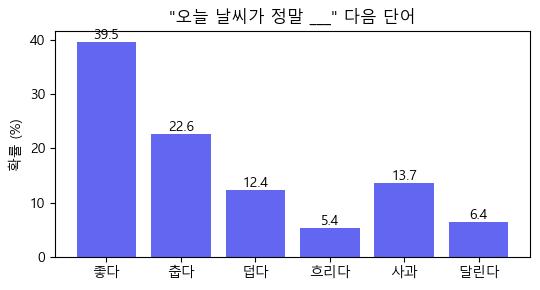

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(5.5, 3))
bars = plt.bar(VOCAB, probs * 100, color='#6366f1')
plt.ylabel('확률 (%)'); plt.title('"오늘 날씨가 정말 ___" 다음 단어')
plt.bar_label(bars, fmt='%.1f')
plt.tight_layout(); plt.show()

## 4. 벡터를 바꾸면 다음 단어가 바뀐다

문맥 벡터의 방향을 '추운 날' 쪽으로 틀면, 뽑히는 단어도 바뀝니다.

In [4]:
for ctx in [[1.0, 0.2], [0.2, 1.2], [-1.0, 0.3]]:
    p = softmax(W_out @ np.array(ctx))
    print(f'벡터 {ctx} → 다음 단어: {VOCAB[int(np.argmax(p))]:5s} ({p.max()*100:.0f}%)')

벡터 [1.0, 0.2] → 다음 단어: 좋다    (40%)
벡터 [0.2, 1.2] → 다음 단어: 춥다    (34%)
벡터 [-1.0, 0.3] → 다음 단어: 흐리다   (36%)


## 5. 직접 해보기 ✏️

문맥 벡터 `(1, 2)` 와 단어 벡터 `(2, 1)` 의 내적(점수)을 구하세요. (웹 StepQuiz 와 같은 문제)

In [5]:
context = np.array([1, 2]); word = np.array([2, 1])
score = context @ word
print('점수(logit):', score)

assert score == 4, '1*2 + 2*1 을 계산하세요!'
print('✅ 1·2 + 2·1 = 4')

점수(logit): 4
✅ 1·2 + 2·1 = 4


---
입력부터 **다음 단어 확률**까지, 조각이 전부 모였습니다! 🎉
다음 챕터(ch10)에서 이 모두를 **한 흐름**으로 이어 GPT가 문장을 쓰는 과정을 완성합니다.
**이 학습의 궁극 목표**입니다. 🏁